In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Weight Decay

In that section a polynomial of degree 19 fit 20
noisy points with weights of a million or more, and we avoided such fits by
choosing the degree on validation data. Choosing the degree is a choice of
features, and with many inputs it is a coarse one. For $k$ input variables,
the number of *monomials* of degree $q$, products of powers such as
$x_1^2 x_2$ whose exponents add up to $q$, is $\binom{k-1+q}{k-1}$. For $k = 20$ there are 20 features of
degree 1, 210 of degree 2, and 1,540 of degree 3. We would like to limit
the flexibility of a model on a continuous scale instead, while keeping all
of its features.

A small example shows where the excess flexibility of a linear model lies.
Suppose that the model receives two features that nearly duplicate each
other, such as the same quantity measured by two instruments, and that the
label is close to their sum, $y \approx x_1 + x_2$. The weights $(1, 1)$
fit the training data. The weights $(501, -499)$ fit them almost as well:
they predict $x_1 + x_2 + 500\,(x_1 - x_2)$, and on the training examples
the two measurements differ only slightly. Least squares chooses among such
weight vectors by how well they fit the noise in the training labels, and
since the small differences $x_1 - x_2$ are noise as well, it can return
large weights of opposite sign. On a new example whose two measurements
differ by 2, the predictions of the two weight vectors differ by 1,000.
With more features than examples the problem is extreme: 200 weights can
fit 20 labels exactly in infinitely many ways, which agree on the training
inputs and disagree on new ones. More data would determine the weights, but
data are often expensive or impossible to collect. Dropping the second
measurement would also help, but that is again a choice of features.

This section keeps all the features and penalizes large weights instead. We
add the squared norm of the weight vector, multiplied by a constant
$\lambda \geq 0$, to the loss. Among weight vectors that fit the data about
equally well, the penalized loss prefers the smallest, $(1, 1)$ in the
example, and $\lambda$ sets the strength of this preference on a continuous
scale. We define the penalty and its effect on gradient descent, watch it
repair a model with 200 features trained on 20 examples, and then ask which
directions in weight space it shrinks.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## Norm Penalties

### The Penalized Loss

The loss of linear regression in that section is the
average squared error over the $n$ training examples,

$$L(\mathbf{w}, b) = \frac{1}{n}\sum_{i=1}^n \frac{1}{2}\left(\mathbf{w}^\top \mathbf{x}^{(i)} + b - y^{(i)}\right)^2.$$

To penalize large weights, we add the squared $\ell_2$ norm
$\|\mathbf{w}\|^2 = \sum_j w_j^2$ of that section,
scaled by a constant $\lambda \geq 0$, and minimize

$$L(\mathbf{w}, b) + \frac{\lambda}{2}\|\mathbf{w}\|^2.$$

The first term measures the errors on the training data and the second the
size of the weights. The *regularization constant* $\lambda$ weighs one
against the other. With $\lambda = 0$ we recover the original loss. As
$\lambda$ grows, the minimizer moves toward $\mathbf{w} = \mathbf{0}$, the
model that ignores its inputs and predicts $b$ everywhere. The training loss
is always lowest at $\lambda = 0$, so it cannot choose $\lambda$. Like the
degree of a polynomial in that section,
$\lambda$ is a hyperparameter, chosen on validation data.

The factor $\frac{1}{2}$ makes the gradient of the penalty simply
$\lambda\mathbf{w}$. We do not penalize the bias: adding a constant to
every label should move the fit by that constant at no cost, whereas a
penalty on $b$ would pull every prediction toward zero rather than toward
the average label.

A change to training whose purpose is to lower the error on new data rather
than on the training data is called *regularization*. The penalty
the equation is the most common regularizer in deep learning,
where it is called weight decay
[@Hanson.Pratt.1988; @Krogh.Hertz.1992] for a reason we see shortly.
Statisticians call linear regression with this penalty *ridge regression*
[@Hoerl.Kennard.1970].

What does a smaller norm change about the model? For a linear model, the
norm bounds how strongly the prediction can respond to a change of the
input. By the Cauchy--Schwarz inequality
$|\mathbf{u}^\top\mathbf{v}| \leq \|\mathbf{u}\|\,\|\mathbf{v}\|$ of
that section, the predictions for two inputs $\mathbf{x}$
and $\mathbf{x}'$ differ by at most

$$|\mathbf{w}^\top \mathbf{x} - \mathbf{w}^\top \mathbf{x}'| \leq \|\mathbf{w}\|\, \|\mathbf{x} - \mathbf{x}'\|.$$

A model with small weights cannot amplify a small change of its input, such
as noise in a measurement. In the opening example, the weights $(1, 1)$
have norm $\sqrt{2} \approx 1.4$ and the weights $(501, -499)$ have norm
about 707, and the second pair turns a difference of 2 between the
measurements into a change of 1,000 in the prediction. This reading relies
on the model being linear, so that its weights are the slopes of the
function it computes. When parameters enter the output in more complicated
ways, as in the networks of later chapters, the same function can be
computed by parameters of very different norms, and the norm of the
parameters is a less direct measure of how much the function can vary.

### Weight Decay in the Gradient Step

The gradient of the penalty $\frac{\lambda}{2}\|\mathbf{w}\|^2$ is
$\lambda\mathbf{w}$. Adding it to the minibatch SGD update of
that section, with learning rate $\eta$
and minibatch $\mathcal{B}_t$, gives

$$\mathbf{w} \leftarrow (1 - \eta\lambda)\,\mathbf{w} - \frac{\eta}{|\mathcal{B}|} \sum_{i \in \mathcal{B}_t} \mathbf{x}^{(i)} \left(\mathbf{w}^\top \mathbf{x}^{(i)} + b - y^{(i)}\right),$$

while the update of $b$ does not change. The update first multiplies the
weights by $1 - \eta\lambda$, a number slightly below one, and then takes
the usual step toward fitting the minibatch. Without the data term, the
weights would decay geometrically, to $(1 - \eta\lambda)^t$ times their
initial value after $t$ steps, which is why the method is called *weight
decay*. With $\eta = 0.01$ and $\lambda = 3$, the values of the experiment
below, each step keeps 97% of the weights, and 120 steps keep
$0.97^{120} \approx 2.6\%$. The data term counteracts the decay along
directions in which the training data favor nonzero weights. Along the
other directions nothing stops it.

For minibatch SGD, adding $\frac{\lambda}{2}\|\mathbf{w}\|^2$ to the loss
and multiplying the weights by $1 - \eta\lambda$ in every step are the same
operation. Frameworks implement weight decay inside the optimizer rather
than in the loss, as we will see at the end of this section. The two forms
differ for optimizers that rescale each coordinate of the gradient, which
exercise 2 explores. An update
that shrinks the weights directly, whatever the optimizer does with the
gradient, is called *decoupled weight decay* [@Loshchilov.Hutter.2019];
that section shows why the distinction matters for adaptive
optimizers.

### The $\ell_1$ Penalty and Sparsity

Other norms give other penalties. With the $\ell_1$ norm
$\|\mathbf{w}\|_1 = \sum_j |w_j|$ in place of the squared $\ell_2$ norm,
linear regression becomes *lasso* regression [@Tibshirani.1996]. The
two penalties treat the duplicated features of the opening differently.
When the two measurements agree, the weights $(1, 1)$ and $(2, 0)$ make the
same predictions. The squared $\ell_2$ norm prefers to spread the weight:
it is 2 for $(1, 1)$ and 4 for $(2, 0)$. The $\ell_1$ norm is 2 for both,
and for every split $(a, 2 - a)$ with $0 \leq a \leq 2$, so lasso has no
preference for an even split.

Geometry explains the difference. Minimizing the penalized loss is
equivalent to minimizing $L$ subject to a bound on the norm
($\|\mathbf{w}\| \leq s$ for ridge, $\|\mathbf{w}\|_1 \leq s$ for lasso),
for a bound $s$ that depends on $\lambda$; the appendix derives
this correspondence (that section). The
contours of the loss, the sets of weight vectors with equal loss, are
ellipses around the unconstrained minimizer $\hat{\mathbf{w}}$, elongated
along the directions that the data determine poorly. The constrained
solution, which we write $\hat{\mathbf{w}}_\lambda$, is the point where the
smallest contour touches the constraint region
(the figure). The $\ell_2$ ball is round, so the contact
point usually has every coordinate nonzero: ridge regression shrinks the
weights but rarely sets one to zero. The $\ell_1$ ball is a diamond with
its corners on the axes, and a contour often touches it first at a corner,
where some coordinates are zero. Lasso therefore selects features, which
helps when only a few of many features matter, or when measuring each
feature has a cost. The rest of this section uses the $\ell_2$ penalty,
whose minimizer has a closed form.

![Weight decay as a constraint. The contours of the training loss are ellipses around the unconstrained minimizer $\hat{\mathbf{w}}$, and the regularized solution $\hat{\mathbf{w}}_\lambda$ is the point where the smallest contour (orange) touches the constraint region. Left: the $\ell_2$ ball is touched where both coordinates are nonzero. Right: the $\ell_1$ diamond is touched at a corner, where $w_2 = 0$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-linreg-ridge-geometry.svg)

### A Gaussian Prior on the Weights

The penalty also has a probabilistic reading, which says how large
$\lambda$ should be. In that section
we derived the squared loss from Gaussian noise. If each label is
$y = \mathbf{w}^\top \mathbf{x} + b + \epsilon$ with
$\epsilon \sim \mathcal{N}(0, \sigma^2)$, the negative log-likelihood of the
training labels is

$$-\log p(\mathbf{y} \mid \mathbf{X}, \mathbf{w}, b) = \frac{1}{2\sigma^2}\sum_{i=1}^n \left(y^{(i)} - \mathbf{w}^\top\mathbf{x}^{(i)} - b\right)^2 + \textrm{const},$$

and maximum likelihood minimizes it.

Maximum likelihood uses only the data. Suppose that before seeing any data
we believe large weights to be unlikely. We can state this belief as a
*prior* distribution on the weights, here independent normal weights
$w_j \sim \mathcal{N}(0, \tau^2)$, whose standard deviation $\tau$ says
how large we expect them to be.

Bayes' theorem (that section) combines the prior with the likelihood
into the *posterior*
$p(\mathbf{w} \mid \mathbf{X}, \mathbf{y}) \propto p(\mathbf{y} \mid \mathbf{X}, \mathbf{w})\, p(\mathbf{w})$,
the distribution of the weights after seeing the data. The weights with the
highest posterior density are the *maximum a posteriori* (MAP) estimate. In
the negative logarithm of the posterior, the prior contributes

$$-\log p(\mathbf{w}) = \frac{1}{2\tau^2}\|\mathbf{w}\|^2 + \textrm{const},$$

a quadratic penalty on the weights. Multiplying the negative log-posterior
by $\sigma^2/n$, which does not move its minimizer, turns it into the
penalized loss the equation with

$$\lambda = \frac{\sigma^2}{n \tau^2}.$$

Weight decay is MAP estimation under a Gaussian prior on the weights. The
formula says how the strength of the penalty should depend on the problem.
It grows with the noise level $\sigma$, since noisy labels deserve less
trust, and it grows as the prior narrows, with smaller $\tau$. It falls as
$1/n$, since more data outweigh the prior. The appendix
treats MAP estimation in general
(that section).

## Weight Decay from Scratch

We now train a model that can overfit, with and without the penalty. The
data come from a linear model with $d = 200$ standard normal features,

$$y = 0.05 + \sum_{j=1}^{200} 0.01\, x_j + \epsilon, \quad \epsilon \sim \mathcal{N}(0, 0.01^2),$$

so the true weights are $\mathbf{w}^* = (0.01, \ldots, 0.01)$ and the true
bias is $b^* = 0.05$. We train on only 20 examples, in minibatches of 5,
and validate on 1,000. With 200 weights and 20 training labels, infinitely
many weight vectors fit the training labels exactly.
`SyntheticRegressionData` from that section
draws such data for any $\mathbf{w}^*$ and $b^*$.

In [2]:
data = d2l.SyntheticRegressionData(w=d2l.ones(200) * 0.01, b=0.05, noise=0.01,
                                   num_train=20, num_val=1000, batch_size=5)

### The Penalized Model

The penalty is half the sum of the squared weights.

In [3]:
def l2_penalty(w):
    return d2l.reduce_sum(w**2) / 2

We extend the linear regression model of that section. It
stores $\mathbf{w}$ and $b$, draws the initial weights from
$\mathcal{N}(0, 0.01^2)$, computes the average squared loss with the factor
$\frac{1}{2}$, and trains with minibatch SGD. Only `training_step` changes:
it returns the penalized loss the equation, which the trainer
differentiates and minimizes. `validation_step` still returns the plain
squared loss, so that validation losses at different values of $\lambda$
all measure the quality of the predictions.

In [4]:
class WeightDecayScratch(d2l.LinearRegressionScratch):
    def __init__(self, num_inputs, lambd, lr, sigma=0.01):
        super().__init__(num_inputs, lr, sigma)
        self.save_hyperparameters()

    def training_step(self, batch):
        loss = super().training_step(batch)
        return loss + self.lambd * l2_penalty(self.w)

### Training with and without the Penalty

`train_scratch` trains a model with regularization constant `lambd`
(`lambda` is a reserved word in Python) on `data` for 30 epochs at learning
rate 0.01, which makes 120 SGD steps. It returns the model, its final
validation loss, read from `trainer.history`, and the norm of the learned
weights. The plot shows the training and validation losses of each epoch on
a logarithmic scale.

In [5]:
def train_scratch(lambd, data):
    trainer = d2l.Trainer(max_epochs=30)
    trainer.board.yscale = 'log'
    model = WeightDecayScratch(num_inputs=200, lambd=lambd, lr=0.01)
    trainer.fit(model, data)
    norm = float(jnp.linalg.norm(model.w[...]))
    return model, trainer.history['val_loss'][-1], norm

Without the penalty, the model fits the training labels exactly, yet its
validation loss stays high.

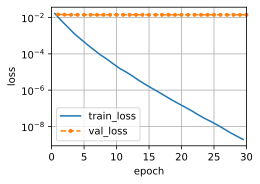

In [6]:
model_0, val_loss, norm = train_scratch(0, data)

In [7]:
print(f'validation loss {val_loss:.4f}, norm of w {norm:.3f}')

validation loss 0.0142, norm of w 0.121


The training loss falls by many orders of magnitude, to below $10^{-7}$:
the model fits all 20 training labels. The validation loss barely moves
and stays near 0.02, between about 0.015 and 0.025 from run to run.
Twenty labels pin down only 20 of the 200 directions in weight space, so
fitting them exactly barely improves the validation loss; why, and why
the penalty helps, is the subject of that section. Now
we add the penalty, with $\lambda = 3$.

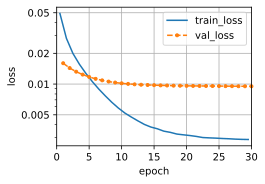

In [8]:
model_3, val_loss, norm = train_scratch(3, data)

In [9]:
print(f'validation loss {val_loss:.4f}, norm of w {norm:.3f}')

validation loss 0.0095, norm of w 0.039


The training curve now shows the penalized loss, which levels off at about
$10^{-3}$ to $10^{-2}$, since small weights cannot fit the training labels
exactly. The validation loss falls steadily, to about 0.01, roughly half
its value without the penalty, and the norm of the weights shrinks from
between 0.12 and 0.16 to between 0.02 and 0.06. Each run draws new data,
so the numbers vary from run to run, but these comparisons do not.

## Shrinkage Along Eigenvectors

Why does the penalty lower the validation loss? For linear regression, the
minimizer of the penalized loss has a closed form, and the closed form
shows which parts of the weights the penalty shrinks. It does two things.
Along directions in weight space that the data determine poorly, it damps
the large coordinates that least squares picks up from noise in the labels.
Along directions that the data do not determine at all, it removes whatever
the weights hold there, including what the initialization put in. The
second effect is what helped in our experiment; a small example below shows
the first.

### The Ridge Estimator

To keep the formulas short, we drop the bias in this section. With a bias,
which is not penalized, the same analysis applies to the data after the
features and the labels are centered to average zero over the training set
(exercise 2). Without the bias, the
loss is $L(\mathbf{w}) = \frac{1}{2n}\|\mathbf{X}\mathbf{w} - \mathbf{y}\|^2$,
with gradient $\frac{1}{n}\mathbf{X}^\top(\mathbf{X}\mathbf{w} - \mathbf{y})$.
Adding the gradient $\lambda\mathbf{w}$ of the penalty and setting the sum
to zero gives

$$\left(\frac{1}{n}\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}\right)\mathbf{w} = \frac{1}{n}\mathbf{X}^\top\mathbf{y}.$$

At $\lambda = 0$ these are the normal equations of
that section, divided by $n$. They
have many solutions when the columns of $\mathbf{X}$ are dependent, as they
are for 20 examples with 200 features. For $\lambda > 0$ the matrix on the
left is invertible: for every $\mathbf{v} \neq \mathbf{0}$,
$\mathbf{v}^\top\left(\frac{1}{n}\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I}\right)\mathbf{v} = \frac{1}{n}\|\mathbf{X}\mathbf{v}\|^2 + \lambda\|\mathbf{v}\|^2 > 0$,
so the matrix maps no nonzero vector to zero. The penalized loss therefore
has exactly one minimizer, the *ridge estimator* $\hat{\mathbf{w}}_\lambda$.

### Shrinkage Factors

The matrix $\frac{1}{n}\mathbf{X}^\top\mathbf{X}$ is symmetric, so it has
perpendicular eigenvectors $\mathbf{v}_1, \ldots, \mathbf{v}_d$ of length 1,
one per dimension, with real eigenvalues $\mu_1, \ldots, \mu_d$
(that section). Each eigenvalue measures how
strongly the training data determine the weights along its eigenvector.
Since
$\mu_j = \mathbf{v}_j^\top \left(\frac{1}{n}\mathbf{X}^\top\mathbf{X}\right) \mathbf{v}_j = \frac{1}{n}\|\mathbf{X}\mathbf{v}_j\|^2$,
moving the weights a unit distance along $\mathbf{v}_j$ changes the
predictions on the training inputs by $\mu_j$ in mean square. The
eigenvalues are never negative, and $\mu_j = 0$ means that the move changes
no training prediction at all.

In the basis of eigenvectors, the equations the equation
separate. We write the weights as $\mathbf{w} = \sum_j c_j \mathbf{v}_j$
and the right-hand side as
$\frac{1}{n}\mathbf{X}^\top\mathbf{y} = \sum_j g_j \mathbf{v}_j$. The
matrix maps $\mathbf{v}_j$ to $(\mu_j + \lambda)\,\mathbf{v}_j$, so the
equations become $(\mu_j + \lambda)\,c_j = g_j$, one for each $j$. Without
the penalty, least squares gives $c_j = g_j/\mu_j$ wherever $\mu_j > 0$.
With the penalty,

$$c_j = \frac{\mu_j}{\mu_j + \lambda} \cdot \frac{g_j}{\mu_j}.$$

The ridge estimator multiplies the least-squares coordinate along each
eigenvector by the *shrinkage factor* $\mu_j/(\mu_j + \lambda)$.

The factor is close to 1 when $\mu_j \gg \lambda$, close to 0 when
$\mu_j \ll \lambda$, and $\frac{1}{2}$ at $\mu_j = \lambda$
(the figure). Directions that the data determine well
keep their coordinates, and directions that they determine poorly are
suppressed. In the poorly determined directions least squares is easily
misled: noise in the labels changes $g_j$ a little, and the least-squares
coordinate $g_j/\mu_j$ a lot when $\mu_j$ is small.

![The shrinkage factor $\mu/(\mu + \lambda)$ of the ridge estimator along an eigenvector with eigenvalue $\mu$, against the regularization constant $\lambda$. A direction keeps its coordinate while $\lambda \ll \mu$ and loses it once $\lambda \gg \mu$; the factor is $\frac{1}{2}$ at $\lambda = \mu$ (dots). Directions with $\mu = 0$ are set to zero for every $\lambda > 0$ (dashed).](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-linreg-ridge-shrinkage.svg)

Directions with $\mu_j = 0$ are the extreme case. There
$g_j = \frac{1}{n}\mathbf{v}_j^\top\mathbf{X}^\top\mathbf{y} = \frac{1}{n}(\mathbf{X}\mathbf{v}_j)^\top\mathbf{y} = 0$,
so the least-squares equation $\mu_j c_j = g_j$ reads $0 = 0$ and leaves
$c_j$ undetermined, while the ridge estimator sets $c_j = 0$ for every
$\lambda > 0$.

Adding up the shrinkage factors gives the *effective number of parameters*
(statisticians say degrees of freedom),

$$\textrm{df}(\lambda) = \sum_{j=1}^d \frac{\mu_j}{\mu_j + \lambda}.$$

A direction counts as one parameter if it is kept, as none if it is
suppressed, and as a fraction in between. As $\lambda$ decreases to 0,
$\textrm{df}$ approaches the number of nonzero eigenvalues, and as
$\lambda$ grows it falls continuously to 0. This is the continuous control
of capacity we asked for at the start of the section. Instead of adding or
removing whole features, $\lambda$ moves the effective number of parameters
through every value in between.

### Two Duplicated Features

The duplicated features of the opening show this damping with numbers. We
draw $n = 100$ examples with $x_1 \sim \mathcal{N}(0, 1)$ and a second
feature $x_2 = x_1 + 0.001\,z$ with $z \sim \mathcal{N}(0, 1)$,
label them $y = x_1 + x_2 + \epsilon$ with $\epsilon \sim \mathcal{N}(0, 0.1^2)$,
and fit without a bias. The sum direction $(1, 1)/\sqrt{2}$ then has an
eigenvalue between about 1 and 3, and the difference direction
$(1, -1)/\sqrt{2}$ one below $10^{-6}$, so at $\lambda = 0.01$ ridge keeps the sum and removes the
difference. The problem needs no framework: NumPy draws the data and solves
both problems in closed form. We test each fit on 1,000 new examples drawn
in the same way and on 1,000 whose features disagree more,
$x_2 = x_1 + 0.1\,z$.

In [10]:
rng = np.random.default_rng()  # A new draw on every run

def twins(n, gap):
    """Two near-copies of a feature, x2 = x1 + gap * noise, labeled by
    y = x1 + x2 + noise with standard deviation 0.1."""
    x1 = rng.normal(size=n)
    X = np.stack([x1, x1 + gap * rng.normal(size=n)], axis=1)
    return X, X.sum(axis=1) + 0.1 * rng.normal(size=n)

def mse(w, data):
    """Mean squared error of the weights w on data = (X, y)."""
    X, y = data
    return ((X @ w - y) ** 2).mean()

We fit two training sets of 100 examples each, by least squares and by
ridge regression at $\lambda = 0.01$.

In [11]:
lambd = 0.01
near, far = twins(1000, 0.001), twins(1000, 0.1)  # the two test sets
for _ in range(2):                                # two training sets
    X, y = twins(100, 0.001)
    w_ls = np.linalg.lstsq(X, y, rcond=None)[0]
    w_ridge = np.linalg.solve(X.T @ X / len(X) + lambd * np.eye(2),
                              X.T @ y / len(X))
    for name, w in (('least squares', w_ls), ('ridge', w_ridge)):
        print(f'{name:>13} ({w[0]:6.2f}, {w[1]:6.2f}): '
              f'test {mse(w, near):.3f}, disagreeing {mse(w, far):.3f}')
mu = np.linalg.eigvalsh(X.T @ X / len(X))         # in increasing order
print(f'eigenvalues of X^T X / n: {mu[0]:.1e}, {mu[1]:.1e}')

least squares ( 13.26, -11.24): test 0.011, disagreeing 1.518
        ridge (  1.00,   1.00): test 0.011, disagreeing 0.011
least squares ( 13.60, -11.60): test 0.011, disagreeing 1.607
        ridge (  0.99,   0.99): test 0.011, disagreeing 0.011
eigenvalues of X^T X / n: 4.1e-07, 1.6e+00


Least squares returns different weights for each training set. They always
add up to about 2, the sum that the data determine, but the split between
them changes from draw to draw, with weights often several units away from
1 and of opposite sign. Ridge returns about $(1, 1)$ every time. On new
examples like the training examples, both fits have a test error of about
0.01, the noise variance $\sigma^2$. On examples whose features disagree
more, least squares fails whenever its weights lie far from 1. Since
$w_2 - 1 \approx -(w_1 - 1)$, its error on such an example is about $(w_1 - 1)(x_1 - x_2)$ plus the noise, with mean
square about $0.01\,(w_1 - 1)^2 + 0.01$: the large weights amplify the
disagreement, as the bound
$|\mathbf{w}^\top \mathbf{x} - \mathbf{w}^\top \mathbf{x}'| \leq \|\mathbf{w}\|\, \|\mathbf{x} - \mathbf{x}'\|$
allows. Ridge keeps its error at about 0.01.

### The Directions Our Data Determine

We now compute the eigenvalues of $\frac{1}{n}\mathbf{X}^\top\mathbf{X}$
for our 20 training inputs and the shrinkage factors at $\lambda = 3$. We
use the raw inputs, not centered ones, because the gradient with respect to
$\mathbf{w}$, which we examine below, is a combination of the raw inputs;
centering would remove one more direction and lower $\textrm{df}(3)$ a
little, to about 14. As in that section, `eigh` returns the eigenvalues in
increasing order and the eigenvectors as the columns of its second result.

In [12]:
X = data.X[:data.num_train]                   # the 20 training inputs
mu, V = jnp.linalg.eigh(X.T @ X / len(X))     # increasing eigenvalues
mu_data = mu[-len(X):]                        # the 20 largest
factors = mu_data / (mu_data + 3)             # shrinkage at lambda = 3
print(f'the other 180 eigenvalues are at most {float(mu[-len(X) - 1]):.0e}')
print(f'mu from {float(mu_data[0]):.1f} to {float(mu_data[-1]):.1f}, '
      f'factors from {float(factors[0]):.2f} to {float(factors[-1]):.2f}, '
      f'df = {float(factors.sum()):.1f}')

the other 180 eigenvalues are at most 2e-06
mu from 4.7 to 16.1, factors from 0.61 to 0.84, df = 15.0


Only the 20 largest eigenvalues are nonzero, between about 4 and 19. The
other 180 are zero up to rounding errors of a few times $10^{-6}$: 20
examples cannot determine more than 20 directions in a 200-dimensional
weight space. At $\lambda = 3$ the shrinkage factors of the 20 determined
directions lie between about 0.6 and 0.85, and $\textrm{df}(3) \approx 15$.
The regularized model has 200 weights but about 15 effective parameters.

The 180 undetermined directions explain the experiment. Gradient descent
never changes the weights along them. The gradient of the unpenalized loss,
$\frac{1}{n}\mathbf{X}^\top\mathbf{r}$ with the errors
$\mathbf{r} = \mathbf{X}\mathbf{w} + b\mathbf{1} - \mathbf{y}$, is a
combination of the training inputs, and every training input is perpendicular to every
$\mathbf{v}_j$ with $\mathbf{X}\mathbf{v}_j = \mathbf{0}$. Without the
penalty, whatever the random initialization put into these directions
stays there. With it, every step multiplies that part by
$1 - \eta\lambda = 0.97$. We split the trained weights of both models into
their part in the 20 determined directions and the rest. Since the columns
of `V_data` are perpendicular and of length 1, `V_data.T @ w` holds the
coordinates of $\mathbf{w}$ along them, and `V_data @ (V_data.T @ w)` is the
projection of $\mathbf{w}$ onto their span.

In [13]:
V_data = V[:, -len(X):]                       # directions the data determine
for lambd, model in ((0, model_0), (3, model_3)):
    w = model.w[...]
    w_data = V_data @ (V_data.T @ w)
    print(f'lambda = {lambd}: '
          f'determined part {float(jnp.linalg.norm(w_data)):.3f}, '
          f'rest {float(jnp.linalg.norm(w - w_data)):.3f}')

lambda = 0: determined part 0.051, rest 0.109
lambda = 3: determined part 0.039, rest 0.003


Without the penalty, the undetermined part has norm about 0.13 (0.11 to
0.15 from run to run), the size of the random initialization in 180
directions, $0.01\sqrt{180} \approx 0.134$.
For a new input $\mathbf{x}$ with standard normal features, this part adds
its dot product with $\mathbf{x}$ to the prediction, an error with variance
equal to its squared norm, about 0.018. With the factor $\frac{1}{2}$ of our
loss, that is 0.009, roughly the difference between the two validation
losses. With $\lambda = 3$, 120 steps shrink the undetermined part by
$0.97^{120} \approx 0.026$, to between 0.003 and 0.004, and the determined part shrinks
by the factors computed above. Shrinking the determined part does not help
here. All 20 of its directions have $\mu_j$ between about 4 and 19, so the
label noise, with $\sigma = 0.01$, moves their least-squares coordinates
very little, unlike the difference direction of the duplicated features.

The penalty cannot recover what the data do not determine. About 180/200
of $\|\mathbf{w}^*\|^2 = 0.02$, or 0.018, lies in the undetermined
directions, so a model that sets its undetermined part to zero, as weight
decay does, has a validation loss of at least about
$\frac{1}{2} \cdot 0.018 = 0.009$. The regularized model comes close to
this limit. Started from $\mathbf{w} = \mathbf{0}$, the unpenalized model
does about as well: its undetermined part stays zero, and its validation
loss is about 0.01, like that of the model with $\lambda = 3$ (exercise
8). As
that section shows, gradient descent on the
squared loss started from zero converges, when it converges at all, to the
interpolating solution of smallest norm. In this experiment, weight decay
helped by removing the random initialization from the directions that 20
examples cannot see. Its other effect, damping the directions that the data
determine poorly, is what the duplicated features showed, and no choice of
starting point provides it.

## Concise Implementation

Weight decay is so common that deep learning frameworks build it into
their optimizers. The optimizer adds $\lambda\mathbf{w}$ to the gradient of
each weight, or equivalently multiplies the weight by $1 - \eta\lambda$, in
the same pass in which it updates the weight, so no penalty needs to
appear in the loss. Frameworks also let different parameters follow
different rules. Below we decay the weights but not the bias.

`optax.sgd` has no weight decay, but optax builds optimizers by chaining
transformations of the gradient. `add_decayed_weights` adds `wd` times the
parameter to its gradient, and `masked` applies it only to the parameters
that a mask selects: here those with more than one dimension, the kernel
but not the bias.

In [14]:
def is_matrix(params):
    """Mask that selects the parameters with more than one dimension."""
    return jax.tree.map(lambda p: p.ndim > 1, params)

class WeightDecay(d2l.LinearRegression):
    def __init__(self, wd, num_inputs, lr, rngs=None):
        super().__init__(num_inputs, lr, rngs)
        self.save_hyperparameters(ignore=['rngs'])

    def configure_optimizers(self):
        return optax.chain(
            optax.masked(optax.add_decayed_weights(self.wd), is_matrix),
            optax.sgd(self.lr))

To reproduce `train_scratch(3, data)` we have to convert the
hyperparameters. The framework losses of that section compute the mean
squared error without our factor $\frac{1}{2}$, so their gradient is twice
ours, and halving the learning rate to 0.005 restores the data step that we
took at 0.01 (that section). The decay
term $\lambda\mathbf{w}$ comes from the optimizer and is not doubled, so
with the halved learning rate the weight decay must double, to 6, for each
step to keep the factor $1 - 0.005 \cdot 6 = 0.97$. With `wd=6` and
`lr=0.005`, every update follows the rule of `train_scratch(3, data)`.

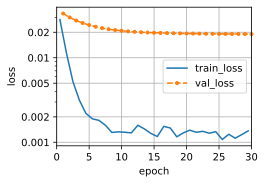

In [15]:
trainer = d2l.Trainer(max_epochs=30)
trainer.board.yscale = 'log'
model = WeightDecay(wd=6, num_inputs=200, lr=0.005)
trainer.fit(model, data)
norm = float(jnp.linalg.norm(model.get_w_b()[0]))

In [16]:
print(f'validation loss {trainer.history["val_loss"][-1]:.4f}, '
      f'norm of w {norm:.3f}')

validation loss 0.0190, norm of w 0.038


The weights end with a norm between 0.02 and 0.06, as in the scratch run
at $\lambda = 3$, and well below the 0.12 to 0.16 of the run without the
penalty.
The validation loss, a mean squared error without the factor $\frac{1}{2}$,
is near 0.02, which corresponds to 0.01 on the scale of our loss. The
training curve now shows the plain mean squared error rather than the
penalized loss, because the decay lives in the optimizer, not in the loss.

We can now control the capacity of a linear model continuously and say
what the control does. The penalty keeps the directions in weight space
that the data determine, damps those that they determine poorly, and
removes those that they do not see. Two questions remain open. The constant
$\lambda$ has to be chosen on validation data, at the cost of one training
run per candidate. And for models whose parameters are not the slopes of
the function they compute, the norm of the parameters no longer bounds
directly how much the function can vary, so what weight decay controls in a
deep network needs a new answer.

## Summary

Weight decay adds the penalty $\frac{\lambda}{2}\|\mathbf{w}\|^2$ to the
loss, so that among weight vectors that fit the data about equally well,
training prefers the smallest. Under minibatch SGD the penalty multiplies
the weights by $1 - \eta\lambda$ in every step, and frameworks implement it
inside the optimizer rather than in the loss. The $\ell_1$ penalty of lasso sets
weights to zero where the $\ell_2$ penalty of ridge regression shrinks
them, and the $\ell_2$ penalty is MAP estimation under a Gaussian prior,
with $\lambda = \sigma^2/(n\tau^2)$. For linear regression, the penalty
multiplies the coordinate along each eigenvector of
$\frac{1}{n}\mathbf{X}^\top\mathbf{X}$ by $\mu_j/(\mu_j + \lambda)$: it
keeps the directions that the data determine, damps those they determine
poorly, and removes those they do not see, so $\lambda$ adjusts the
effective number of parameters continuously. For two duplicated features,
ridge returned weights near $(1, 1)$ where least squares returned large
weights of opposite sign. With 200 features and 20 training examples,
weight decay roughly halved the validation loss by removing the random
initialization from the 180 directions that 20 examples cannot see;
started from zero, the unpenalized model does about as well.

## Exercises

1. **The $\ell_1$ update.** Replace the penalty
   $\frac{\lambda}{2}\|\mathbf{w}\|^2$ by $\lambda \sum_j |w_j|$.
    1. Derive the minibatch SGD update for $\mathbf{w}$, using the
       subgradient $\operatorname{sign}(w_j)$ of
       that section in place of the derivative of
       $|w_j|$.
    1. Compare the change that the penalty alone makes to $w_j$ in one step
       of this update with the change it makes in the update
       the equation, once for large and once for small $|w_j|$.
    1. The update of (a) almost never sets $w_j$ exactly to zero. Split it
       into a gradient step on $L$ followed by the penalty step, and modify
       the penalty step so that it sets $w_j$ to zero whenever it would
       change the sign of $w_j$. Relate the result to the feature selection
       that lasso performs. The modified step is *soft-thresholding*, the
       proximal step of the $\ell_1$ norm
       (that section).

1. **Shrinkage versus penalty.** Weight decay can be applied by shrinking
   the weights before the gradient step or by adding
   $\frac{\lambda}{2}\|\mathbf{w}\|^2$ to the loss $L$.
    1. Show that the update
       $\mathbf{w} \leftarrow (1-\eta\lambda)\mathbf{w} - \eta\nabla L$ is
       identical to a gradient step on the penalized loss
       $L + \frac{\lambda}{2}\|\mathbf{w}\|^2$.
    1. Suppose that the gradient is rescaled coordinate-wise by fixed
       constants $a_j > 0$ before the step. Shrinking and then stepping
       gives the first update below, and stepping on the penalized gradient
       gives the second:

       $$w_j \leftarrow (1-\eta\lambda)\, w_j - \eta a_j \,\partial_{w_j} L
       \qquad \textrm{and} \qquad
       w_j \leftarrow w_j - \eta a_j \left(\partial_{w_j} L + \lambda w_j\right).$$

       Determine for which $a_j$ the two coincide, and the factor by which
       the second update shrinks $w_j$ in a step with
       $\partial_{w_j} L = 0$. Many optimizers used in deep learning
       rescale the gradient in this way. Which of the two updates keeps
       $\lambda$ a rate of decay that is the same for every weight?

    *Adapted from Simon Prince,
    [Understanding Deep Learning](https://udlbook.github.io/udlbook/),
    Problem 9.5.*

1. **MAP estimation.** For the prior
   $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \tau^2\mathbf{I})$ and noise
   variance $\sigma^2$, this section derived
   $\lambda = \sigma^2/(n\tau^2)$.
    1. For `train_scratch(3, data)` ($n = 20$, $\sigma = 0.01$,
       $\lambda = 3$), compute $\tau$ and compare it with the true weights $w^*_j = 0.01$.
       Is the implied prior consistent with the process that generated the
       data? Compute the $\lambda$ that a prior with $\tau = 0.01$ implies.
    1. Holding $\tau$ and $\sigma$ fixed, describe how $\lambda$ changes as
       $n$ grows, and interpret the change in terms of the relative weight
       of prior and likelihood.
    1. The bias $b$ is not penalized. Which prior on $b$ does this
       correspond to?

1. [code] **Ridge as augmented least squares.** Center the 20 training
   inputs and labels so that the bias drops out, and compute the ridge
   estimator for $\lambda = 3$ in two ways.
    1. Solve the linear system the equation.
    1. Run ordinary least squares with `lstsq` on $\mathbf{X}$ stacked on
       top of $\sqrt{n\lambda}\,\mathbf{I}$, with the labels $\mathbf{y}$
       followed by $d$ zeros.

    Confirm that the two agree up to rounding errors, and explain why. Then
    compare the norm of the result with the norm that
    `train_scratch(3, data)` returned, and name the differences between the two procedures that
    could account for any gap.

    *Adapted from Hastie, Tibshirani, and Friedman,
    [The Elements of Statistical Learning](https://hastie.su.domains/ElemStatLearn/),
    Exercise 3.12.*

1. [code] **The $\lambda$ sweep.** Train `WeightDecayScratch` on `data`
   for $\lambda \in \{0.01, 0.1, 0.3, 1, 3, 10, 30\}$.
    1. Plot the final validation loss and the norm of $\mathbf{w}$ against
       $\lambda$ on a logarithmic axis, with the values of
       `train_scratch(0, data)` as horizontal lines, and report the $\lambda$ with the smallest
       validation loss.
    1. Compute $\textrm{df}(\lambda)$ for the same values from the
       eigenvalues of that section, and plot the
       validation loss against $\textrm{df}(\lambda)$. Compare the shape
       with the figure.
    1. Exercise 3 suggests $\lambda = 0.05$.
       Compare the validation loss of the ridge estimator at
       $\lambda = 0.05$, computed as in exercise
       4, with that of
       `WeightDecayScratch` trained for 30 epochs at the same $\lambda$.
       Explain the difference with the decay factor
       $(1 - \eta\lambda)^t$, and estimate how many epochs training would
       need to close the gap.

1. [code] **Stopping early versus decay.** Train `WeightDecayScratch` with
   $\lambda = 0$ for 30 epochs and find the epoch with the lowest
   validation loss in `trainer.history`. Compare that loss with the final
   validation losses of `train_scratch(0, data)` and
   `train_scratch(3, data)`. Use the split of the weights in
   that section to explain why stopping early cannot do
   here what weight decay does.

1. [code] **Duplicated features.** Use the functions `twins` and `mse`
   of that section.
    1. Sweep $\lambda$ over $10^{-8}, 10^{-7}, \ldots, 10$ and plot both
       ridge weights and both test errors against $\lambda$ on a
       logarithmic axis. For which range of $\lambda$ does ridge do well on
       both test sets? Relate the two ends of the range to the two
       eigenvalues of $\frac{1}{n}\mathbf{X}^\top\mathbf{X}$.
    1. Run gradient descent on the unpenalized loss from $\mathbf{w} = \mathbf{0}$
       with learning rate 0.1 for $10^2$, $10^4$, and $10^6$ steps. Compare
       the weights and test errors with those of least squares and ridge,
       and explain the result with the factor $(1 - \eta\mu_j)^t$ of each
       eigenvector.
    1. Fit least squares to labels without noise, $y = x_1 + x_2$. What
       changes, and why?

1. [code] **Starting point.** ● `WeightDecayScratch` draws its initial
   weights from $\mathcal{N}(0, 0.01^2)$.
    1. Train with $\lambda = 0$ and with $\lambda = 3$ starting from
       $\mathbf{w} = \mathbf{0}$ (pass `sigma=0`). Before you run, predict
       both validation losses and the norms of both parts of the weights
       from the split in that section; then compare.
    1. Is the part of $\mathbf{w}$ in the undetermined directions exactly
       unchanged by training at $\lambda = 0$, or only approximately?
       Record the initial weights of a model, train it, and measure.
       Consider minibatch SGD, the bias, and rounding.
    1. Which part of the benefit of weight decay in this section's
       experiment comes from the initialization, and which part would
       remain for data with strongly correlated features, as in exercise
       7?

[Discussions](https://d2l.discourse.group/t/17979)